## MTL Trajet: 08 Rush-hour Usage Destination Anomalies (Flag 8)

### Dataset Overview
MTL urban trajectories with usage, rush-hour timing, route directness, speed, destination land-use, endpoints, and timestamped point records.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify overall situation across all usages for morning and evening rush hours and find some anomalies during this period.

Role: Urban trajectory analyst


Category: Rush-hour usage, speed, route directness, destination land-use, and spatial anomalies

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which usages account for the largest share of trips during rush hours?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

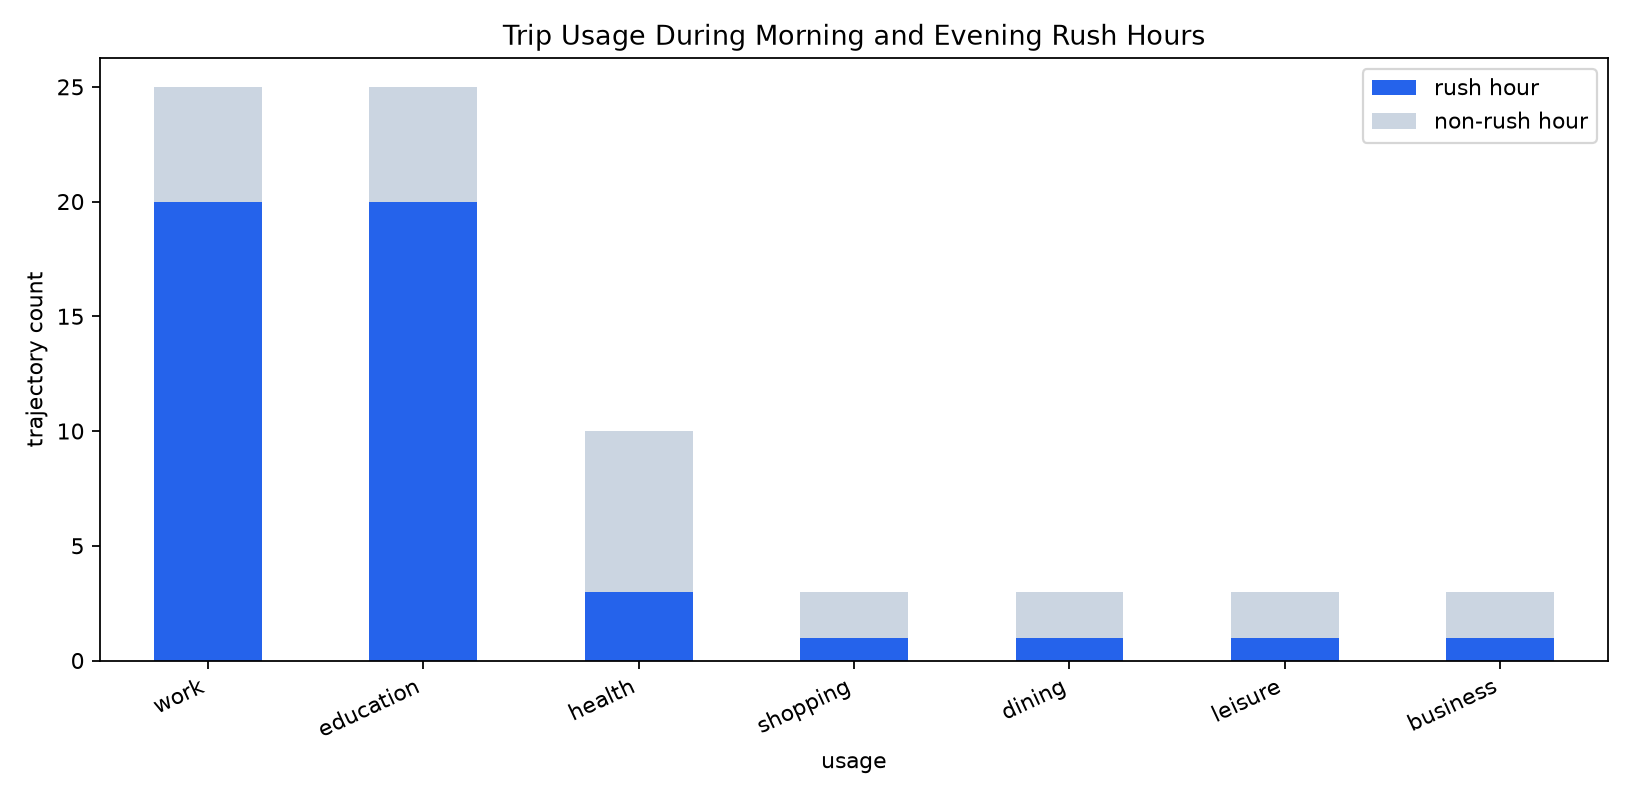

In [ ]:
pd.crosstab(df.usage, df.time_period)
from IPython.display import Image, display
display(Image(filename='visualizations/rush_hour_usage_composition.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "rush_hour_usage_composition",
  "insight": "Work and education account for the largest shares of rush-hour trips.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Rush-hour Trip Usage",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/rush_hour_usage_composition.png"
  },
  "question": "Which usages account for the largest share of trips during rush hours?",
  "code": "pd.crosstab(df.usage, df.time_period)",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: How do speed and route-directness distributions vary across the usage groups?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

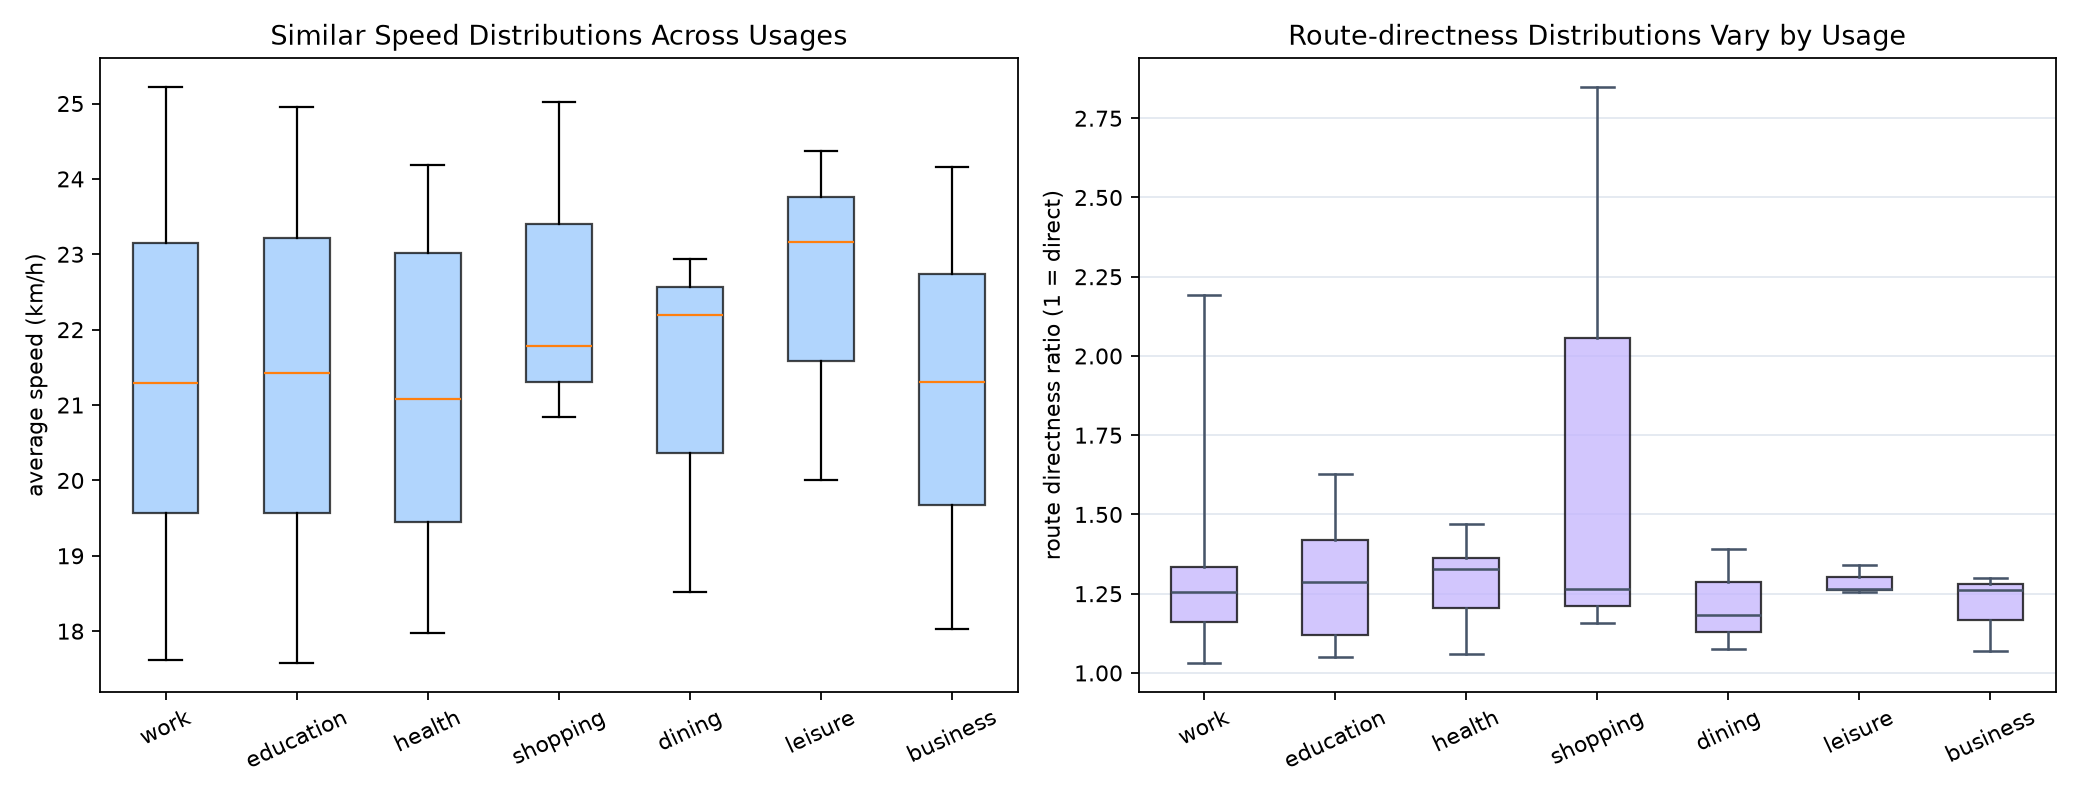

In [ ]:
df.groupby('usage')[['avg_speed_kmh','route_directness_ratio']].agg(['mean','median','std'])
from IPython.display import Image, display
display(Image(filename='visualizations/speed_directness_by_usage.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "usage_speed_directness_distribution",
  "insight": "Speed distributions are generally similar across usage groups, whereas route-directness distributions vary across them.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Speed and Route Directness Across Usages",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/speed_directness_by_usage.png"
  },
  "question": "How do speed and route-directness distributions vary across the usage groups?",
  "code": "df.groupby('usage')[['avg_speed_kmh','route_directness_ratio']].agg(['mean','median','std'])",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "point_speed",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: Which land-use type dominates destinations, and where are these destinations located?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

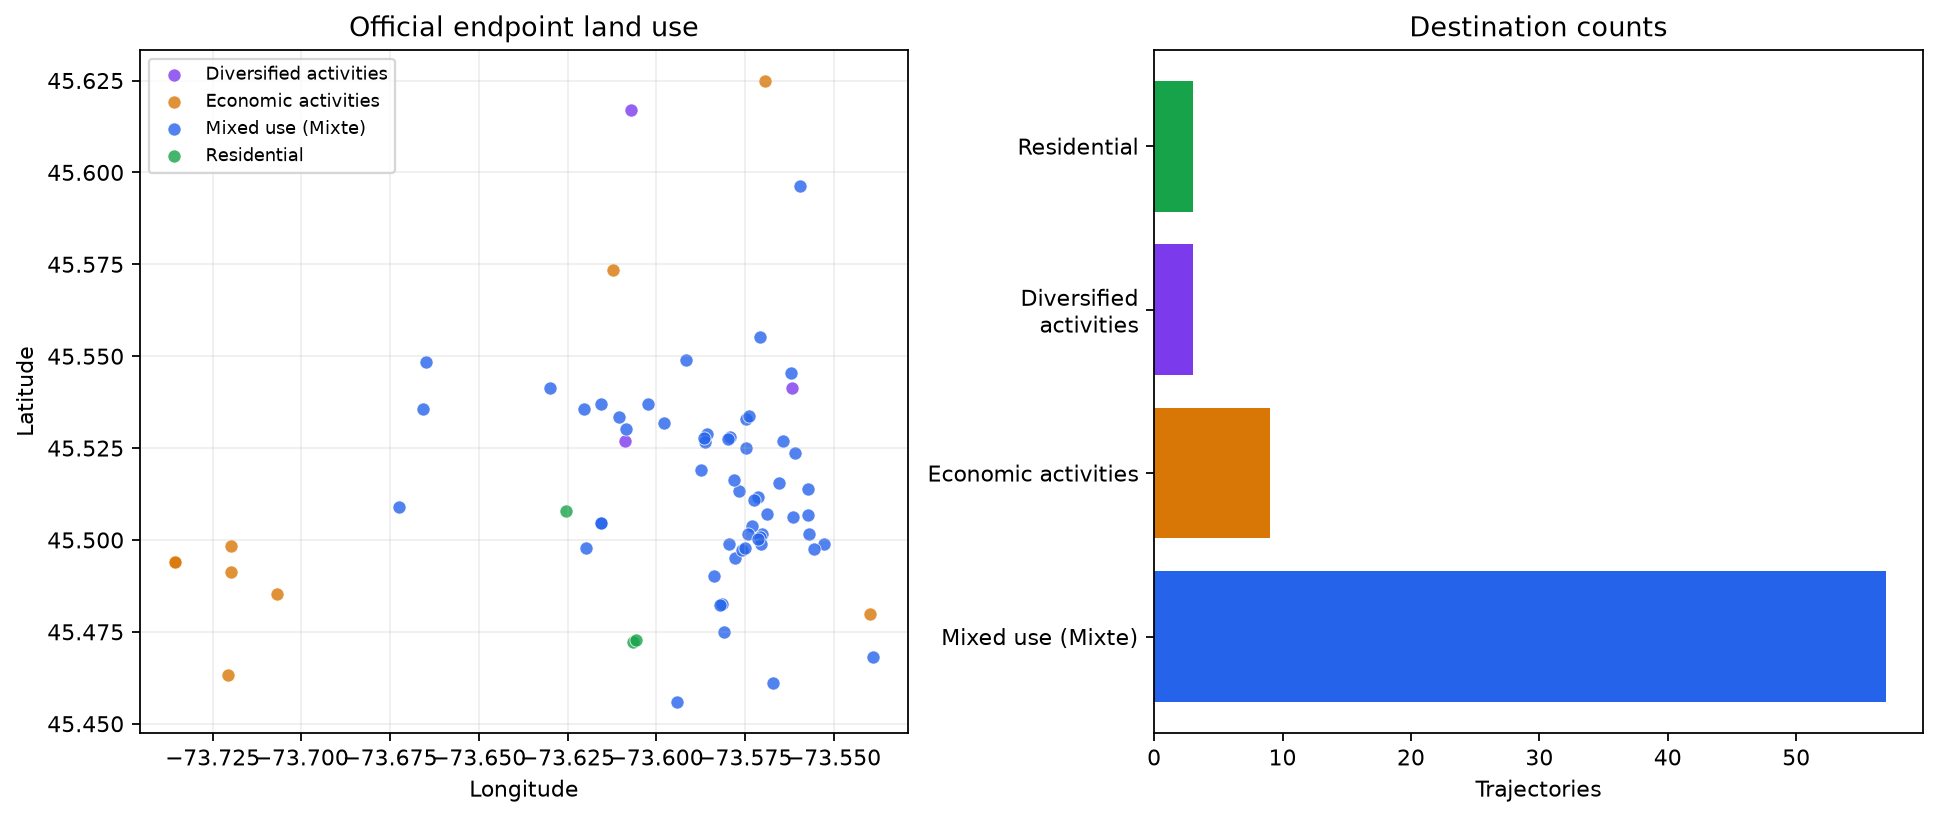

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
df = pd.read_csv(dataset_path)
points = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))
print(pd.crosstab(df.destination_land_use, df.destination_area))

from IPython.display import Image, display
display(Image(filename='visualizations/destination_land_use_city_center.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "destination_land_use_spatial_distribution",
  "insight": "Most trajectories end in Mixte destinations in the city-center area.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Destination Land-use and City-center Pattern",
    "description": "Recomputed from the delivered fixed GPS coordinates and the archived official PUM2050 Affectatio polygons; Unmapped denotes no containing polygon.",
    "file": "visualizations/destination_land_use_city_center.png"
  },
  "question": "Which land-use type dominates destinations, and where are these destinations located?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\ndf = pd.read_csv(dataset_path)\npoints = pd.read_csv(Path(dataset_path).with_name('trajectory_points.csv'))\nprint(pd.crosstab(df.destination_land_use, df.destination_area))\n",
  "insight_value": {
    "Mixte": 57,
    "Activités économiques": 9,
    "Activités diversifiées": 3,
    "Résidentiel": 3
  },
  "evidence": "57 of 72 endpoints fall in official Mixte polygons; destination-area labels are shown separately from land-use categories.",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "land_use_reference",
    "trajectory_id"
  ]
}

### **Question 4**: Which health-relevant trajectories are unusually direct, and where do they travel from and to?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

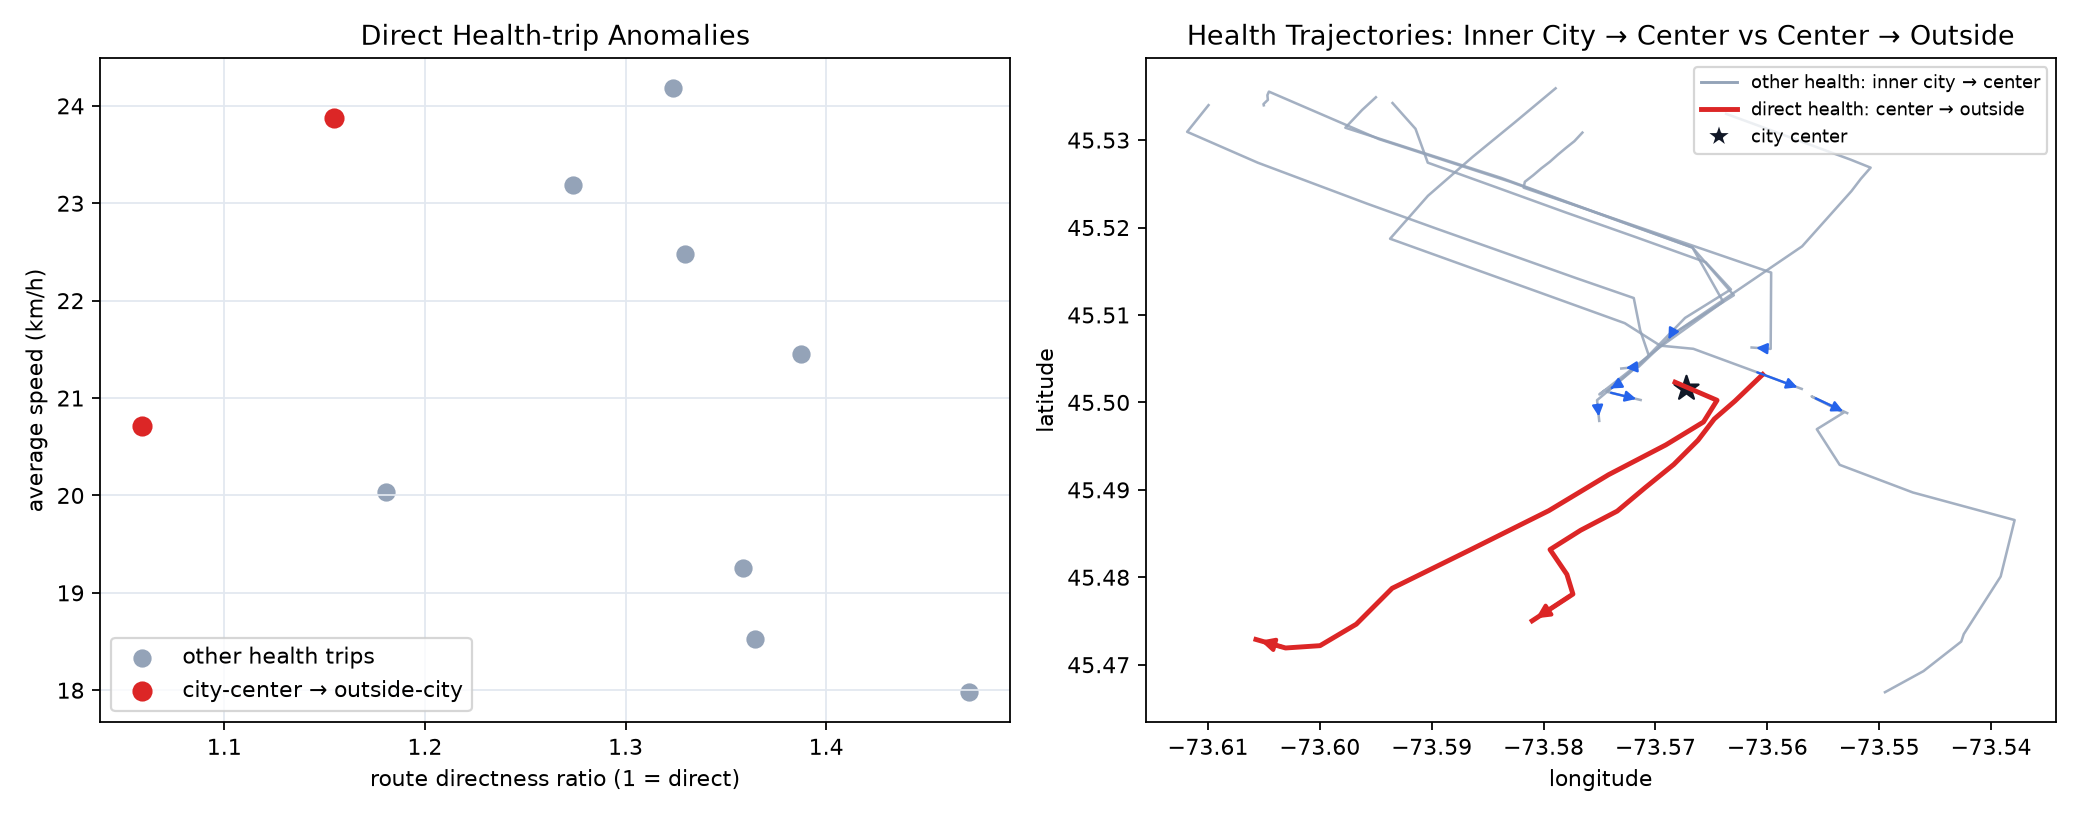

In [ ]:
df[df.usage.eq('health')][['route_directness_ratio','origin_area','destination_area']].sort_values('route_directness_ratio')
from IPython.display import Image, display
display(Image(filename='visualizations/health_direct_route_anomalies.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "health_direct_route_exception",
  "insight": "A small number of health-related trajectories are unusually direct and travel from the city center to outside the city.",
  "insight_type": "exception_deviation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Direct Health-route Anomalies",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/health_direct_route_anomalies.png"
  },
  "question": "Which health-relevant trajectories are unusually direct, and where do they travel from and to?",
  "code": "df[df.usage.eq('health')][['route_directness_ratio','origin_area','destination_area']].sort_values('route_directness_ratio')",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_id",
    "point_speed"
  ]
}

### Summary of Findings (Flag 8)

Work and education account for the largest shares of rush-hour trips. Speed distributions are generally similar across usage groups, whereas route-directness distributions vary across them. Most trajectories end in Mixte destinations in the city-center area. A small number of health-related trajectories are unusually direct and travel from the city center to outside the city.
